# 03 · Interpretabilidad: qué aprendió el modelo, contra una respuesta conocida

Notebook de la fase 3. Es narrativa: toda la lógica vive en `src/fraud_detection/` y aquí solo
se importa. Explica **el artefacto único** del proyecto (ADR 0010), cargado del disco: nada se
reajusta, porque un modelo reconstruido para la explicación explicaría otro objeto. Lee **solo
el periodo de referencia**, y todo lo que mide es *in-sample*: el artefacto se ajustó con esas
mismas filas, así que dice qué usa el modelo, no cuánto generaliza.

Las figuras se regeneran aquí desde `src/`; no se incrustan imágenes guardadas.
`scripts/run_interpretability.py` mide lo mismo, escribe las figuras en
`reports/interpretability/` y las adjunta a la versión 1 del Model Registry (sección 7). El diseño
y sus razones están en el ADR 0011; las cifras de registro, en `docs/analysis/interpretability.md`.

In [1]:
import os
import warnings

# Avisos de importación y de formato que no son del análisis e imprimirían rutas locales: la
# pista de MLflow, que importa `models.registry`; la de tqdm, que importa shap; y el cambio de
# formato de salida de shap para LightGBM, que `shap_values` ya controla: verifica la forma de
# los valores y que cada fila sume su salida cruda.
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud_detection.data import profiling
from fraud_detection.data.schema import TARGET_COLUMN
from fraud_detection.explain.global_explain import (
    FULL_RANGE_COLUMN,
    ICE_COLUMNS,
    ICE_CURVES_PER_GROUP,
    PERMUTATION_REPEATS,
    SIGNATURE_FEATURES,
    compare_rankings,
    explanation_sample,
    grid_side,
    ice_curves,
    log_grid,
    mean_abs_shap,
    model_features,
    model_importance,
    permutation_importance,
    plot_beeswarm,
    plot_ice,
    raw_grid,
    raw_split_thresholds,
    rule_groups,
    shap_values,
    signature_gate,
    trees_splitting_on,
)
from fraud_detection.explain.local_explain import (
    CASE_FALSE_POSITIVE,
    CASE_MODEL_ONLY,
    CASE_NEAR_THRESHOLD,
    CASE_RULE_AND_MODEL,
    CASE_TITLES,
    display_values,
    operating_point,
    plot_waterfall,
    select_cases,
    top_contributions,
)
from fraud_detection.models.baseline import SignatureRule
from fraud_detection.models.evaluation import (
    derived_seeds,
    features_and_labels,
    load_evaluation_frame,
)
from fraud_detection.models.registry import ARTIFACT_PATH, MODEL_INPUT_COLUMNS, load_pipeline
from fraud_detection.models.tracking import file_sha256
from fraud_detection.monitoring.performance import OPERATING_THRESHOLD

pd.set_option("display.float_format", "{:.6g}".format)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", None)
plt.rcParams["figure.dpi"] = 80
FLAG = SIGNATURE_FEATURES[0]
MONEY = ("amount", "oldbalanceOrg", "oldbalanceDest")

## 1. La ventaja de este proyecto: la respuesta se conoce de antemano

Casi nunca se puede validar una explicación: nadie sabe qué *debería* haber aprendido el
modelo. Aquí sí. La firma del simulador —una transferencia o un retiro que se lleva el saldo
completo— marca fraude con precisión 1,000 y recall 0,979 en referencia (ADR 0007), y un modelo
que llega a 0,997 tiene que estar usándola. Es la única oportunidad del proyecto de validar el
**instrumento** de interpretabilidad contra una verdad ya sabida.

Por eso, **antes de producir una sola figura, SHAP tiene que encontrar la firma**. Es la compuerta
del paso 0 (ADR 0011):

- las tres features que codifican la firma —la bandera `amount_equals_origin_balance`, `amount` y
  `oldbalanceOrg`, de las que la bandera se calcula— tienen que sumar **más de la mitad** del
  |SHAP| medio;
- la bandera tiene que estar **entre las tres primeras**;
- si dominan la hora o las columnas de `type`, el roto es el explicador y no el modelo, y aquí se
  para.

La formulación original pedía que la bandera quedara primera. El Arquitecto la corrigió **antes de
medir**: con tres features perfectamente dependientes, el crédito se reparte según la estructura
de cada árbol, y exigir el primer puesto podía fallar por una razón que no es de SHAP.

**El explicador** es `TreeExplainer` *path-dependent*; la sección 3 dice por qué. **La muestra**
son los 4.477 fraudes de referencia y 20.000 legítimas tomadas con `settings.RANDOM_STATE`, las del
gráfico 6 del notebook 01: una muestra uniforme, con 0,08% de fraude, no tendría fraudes
suficientes para que SHAP dijera algo de ellos.

In [3]:
ADR_0010_SHA256 = "41869ee0e5239ca66e0024a10bff4b727cf7ba0a6b6a8087a45da010de5d4ebd"
assert file_sha256(ARTIFACT_PATH) == ADR_0010_SHA256
pipeline = load_pipeline(ARTIFACT_PATH)
model = pipeline[-1]
reference = load_evaluation_frame()
sample = explanation_sample(reference)
sample_rows = sample.drop(columns=[TARGET_COLUMN])
result = shap_values(pipeline, sample_rows)
table = mean_abs_shap(result.values)
gate = signature_gate(table)

print(f"Artefacto {ARTIFACT_PATH.name}, el del ADR 0010")
print(f"Muestra: {len(sample)} filas, {int(sample[TARGET_COLUMN].sum())} fraudes")
print(
    f"Valor base {result.base_value:.4f} log-odds; la suma de los SHAP de cada fila se aparta de "
    f"su salida cruda {result.max_additivity_gap:.1e} como máximo"
)
print(
    f"Las tres features de la firma suman el {gate.signature_share:.1%} del |SHAP| medio; "
    f"la bandera es la {gate.flag_rank}.ª. Compuerta: {'PASA' if gate.passed else 'FALLA'}"
)
assert gate.passed, "SHAP no encontró la firma: el problema es el explicador, no el modelo"
pd.DataFrame(
    {
        "|SHAP| medio": table,
        "parte del total": table / table.sum(),
        "firma": ["sí" if name in SIGNATURE_FEATURES else "" for name in table.index],
    }
)

Artefacto fraud_detection_pipeline.pkl, el del ADR 0010
Muestra: 24477 filas, 4477 fraudes
Valor base -9.5829 log-odds; la suma de los SHAP de cada fila se aparta de su salida cruda 1.8e-13 como máximo
Las tres features de la firma suman el 89.2% del |SHAP| medio; la bandera es la 1.ª. Compuerta: PASA


,|SHAP| medio,parte del total,firma
amount_equals_origin_balance,6.19683,0.798054,sí
oldbalanceOrg,0.470215,0.0605563,sí
oldbalanceDest,0.358073,0.0461142,
amount,0.262073,0.0337509,sí
type_CASH_OUT,0.232642,0.0299606,
hour_sin,0.084593,0.0108942,
type_TRANSFER,0.0703381,0.00905843,
type_PAYMENT,0.0354481,0.00456515,
hour_cos,0.0308633,0.0039747,
type_CASH_IN,0.023853,0.00307188,


**La compuerta pasa.** Las tres features de la firma suman el **89,2%** del |SHAP| medio, y la
bandera es **primera, con el 79,8%**. Los valores SHAP de cada fila suman su salida cruda con un
error de 1,8e-13 log-odds: el explicador explica este modelo y no otro. Con el instrumento
validado contra la respuesta conocida, lo que dice del resto significa algo.

El reparto del crédito entre las tres, 79,8%, 6,1% y 3,4%, es lo esperable de features
perfectamente dependientes bajo *path-dependent*, no un hallazgo (ADR 0011): no dice que `amount`
importe poco, dice que la bandera se llevó el crédito de la igualdad que las tres codifican.

**Por qué esta medida.** Un valor SHAP es cuánto movió una feature la salida de una fila, en
log-odds, y los de cada fila suman exactamente su salida: es la única descomposición que cumple
eso para cada transacción. El promedio se toma en valor absoluto porque un empuje hacia fraude y
otro hacia legítima se cancelarían, y se expresa como parte del total porque la compuerta pregunta
por proporciones, no por log-odds. **Qué significaría que se moviera:** una parte de la firma por
debajo de la mitad, o la hora o los tipos arriba, diría que el explicador no ve lo que se sabe que
el modelo usa, y nada de lo que sigue sería creíble. Por eso la celda tiene un `assert`.

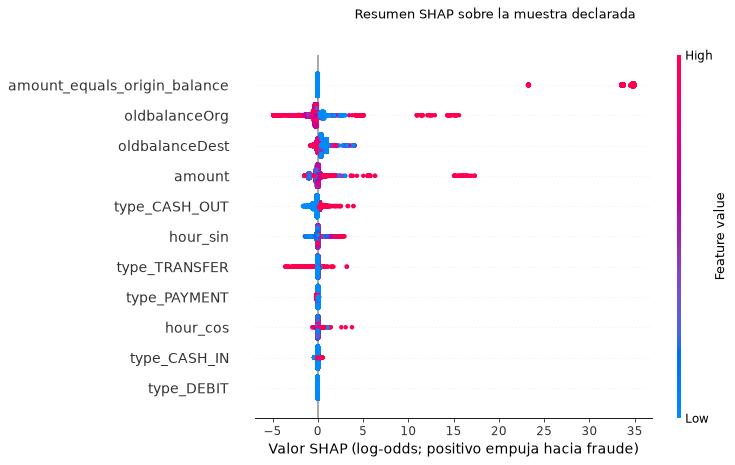

In [4]:
figure = plot_beeswarm(result)
plt.show()

**Figura 1.** Cada punto es una fila de la muestra en una feature; el color es el valor de la
feature, rojo cuando es alto. La bandera parte la muestra en dos: casi todas las filas, sin la
firma, cerca de 0, y las 4.385 filas con la firma muy a la derecha, en dos cúmulos cerca de +23 y
de +35 log-odds. Ninguna otra feature se acerca a ese empuje. Los dos cúmulos no vienen de otros
árboles, porque la bandera se usa en un solo corte (sección 2): en *path-dependent*, el valor
esperado sin la bandera recorre la rama falsa siguiendo las demás features de la fila, y donde
esas features ya apuntan a fraude, la bandera agrega menos.

Después de la bandera, un grupo de filas con saldo de origen y monto altos recibe empujes de +11 a
+17 en `oldbalanceOrg` y `amount`; el caso b de la sección 5, con +11,59 y +15,43, es una de ellas.
`type_TRANSFER` en 1 empuja hacia legítima, hasta −4.

**La consecuencia operativa.** De las 4.510 transacciones que el modelo manda a revisión en
referencia, 4.385 llevan la firma (sección 5): para el 97% de la cola, la explicación que recibe el
analista cabe en una frase, "se lleva el saldo completo de la cuenta". El trabajo de explicar de
verdad está en las 125 restantes, y de esas tratan los casos b, c y d.

## 2. Global: tres ordenaciones lado a lado

Tres maneras de preguntar qué feature importa, y cada una pregunta otra cosa:

- **SHAP**: cuánto mueve cada feature la salida de cada fila, en promedio, sobre la muestra.
- **Permutación**: cuánto cae la métrica de decisión, recall con precisión ≥ 0,99, al barajar una
  feature, sobre las 5.787.030 filas de referencia, con 10 permutaciones por feature. Tarda unos
  minutos: es el único cálculo pesado del notebook.
- **La importancia interna de LightGBM**: *split*, cuántos nodos cortan sobre la feature en los 98
  árboles, y *gain*, cuánta ganancia suman esos cortes.

Se reportan lado a lado, y **donde discrepan se reporta sin resolver a favor de ninguna** (ADR
0011).

In [5]:
raw_rows, labels = features_and_labels(reference)
features = model_features(pipeline, raw_rows)
scores = pd.Series(model.predict_proba(features)[:, 1], index=raw_rows.index)
permutation = permutation_importance(model, features, labels, derived_seeds(PERMUTATION_REPEATS))
summary = permutation.summary()
summary["≈ fraudes"] = summary["mean"] * labels.sum()
print(
    f"Métrica de decisión sin permutar, in-sample: {permutation.baseline:.6f}; "
    f"un fraude es {1 / labels.sum():.6f} de recall"
)
summary

Métrica de decisión sin permutar, in-sample: 0.997543; un fraude es 0.000223 de recall


,mean,std,min,max,≈ fraudes
amount_equals_origin_balance,0.997521,7.06339e-05,0.99732,0.997543,4465.9
amount,0.10478,0.000818662,0.103864,0.106321,469.1
oldbalanceOrg,0.0398481,0.00131597,0.0386419,0.0422158,178.4
oldbalanceDest,0.00614251,0.000353169,0.0055841,0.00670092,27.5
type_CASH_OUT,0.00536073,0,0.00536073,0.00536073,24
hour_cos,0.00341747,0.000408484,0.00290373,0.00402055,15.3
hour_sin,0.00261336,0.000333803,0.00223364,0.00335046,11.7
type_TRANSFER,0.000424391,7.06339e-05,0.000223364,0.000446728,1.9
type_PAYMENT,3.33067e-17,0.000182376,-0.000223364,0.000223364,1.49114e-13
type_CASH_IN,0,0,0,0,0


**Por qué la permutación se mide sobre la métrica de decisión, y en fraudes.** Sobre la exactitud,
barajar una feature apenas movería nada: casi todo es legítimo y seguiría clasificado como
legítimo. Sobre la métrica de decisión, la caída se lee directamente como fraudes que el modelo
deja de atrapar con la cola limpia, que es lo que pierde el negocio si esa feature se rompe. La
columna "≈ fraudes" es esa caída sobre los 4.477 fraudes de referencia.

**Lo que dice cada caída.** Barajar la bandera deja escapar 4.466 fraudes: toda la detección. La
lectura más probable, no medida, es que barajarla no solo quita la firma a los fraudes: se la pone
a unas 4.385 legítimas al azar, que suben a la cabeza del ranking, y ningún umbral vuelve a tener
precisión 0,99. Es la objeción de la sección 3 en su forma más extrema. `amount` cuesta 469, y
`oldbalanceOrg` 178. **La hora cuesta 11,7 y 15,3 fraudes**, por debajo de
la significancia práctica de unos 22: el modelo apenas la usa. Esa cifra tuvo consecuencia en la
fase 4: en producción la hora fue la única feature con drift significativo, PSI 0,32 y 0,33, y el
recall no se movió (notebook 04). Si la caída de la hora hubiera sido grande, ese drift habría sido
una alarma. `type_PAYMENT` marca el piso de ruido: un fraude de más o de menos según la semilla.

In [6]:
importance = model_importance(pipeline)
orderings = compare_rankings(
    {
        "shap": table,
        "permutation": summary["mean"],
        "split": importance["split"],
        "gain": importance["gain"],
    }
)
del features
orderings

,shap,shap_rank,permutation,permutation_rank,split,split_rank,gain,gain_rank
amount_equals_origin_balance,6.19683,1,0.997521,1,1,10,1.92585e+08,1
oldbalanceOrg,0.470215,2,0.0398481,3,873,3,2.41143e+06,2
oldbalanceDest,0.358073,3,0.00614251,4,1181,2,158037,4
amount,0.262073,4,0.10478,2,1227,1,282871,3
type_CASH_OUT,0.232642,5,0.00536073,5,84,7,29850.7,5
hour_sin,0.084593,6,0.00261336,7,471,4,23315.3,6
type_TRANSFER,0.0703381,7,0.000424391,8,90,6,1637.98,8
type_PAYMENT,0.0354481,8,3.33067e-17,9,16,8,727.137,9
hour_cos,0.0308633,9,0.00341747,6,390,5,19607.7,7
type_CASH_IN,0.023853,10,0,10,16,8,214.473,10


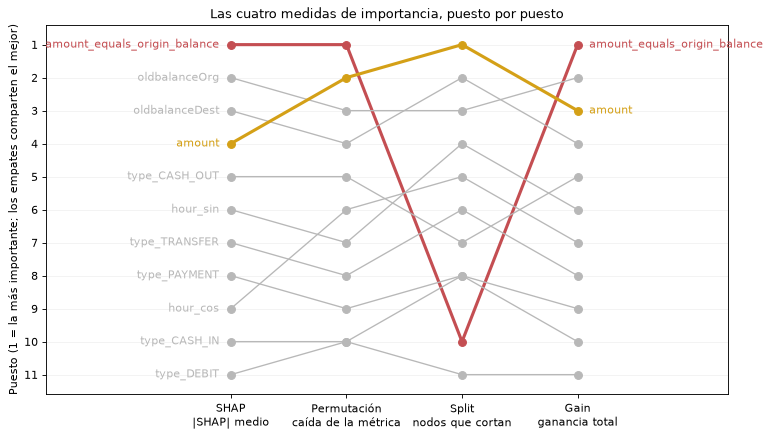

In [7]:
measures = {
    "shap": "SHAP\n|SHAP| medio",
    "permutation": "Permutación\ncaída de la métrica",
    "split": "Split\nnodos que cortan",
    "gain": "Gain\nganancia total",
}
highlight = {FLAG: "#c44e52", "amount": "#d4a017"}
ranks = orderings[[f"{name}_rank" for name in measures]]
fig, ax = plt.subplots(figsize=(11, 6))
for feature, row in ranks.iterrows():
    color = highlight.get(feature, "0.72")
    width = 2.8 if feature in highlight else 1.2
    ax.plot(range(len(measures)), row.to_numpy(), "o-", color=color, lw=width, ms=7)
    ax.text(-0.1, row.iloc[0], feature, ha="right", va="center", color=color, fontsize=10)
for feature, color in highlight.items():
    row = ranks.loc[feature]
    ax.text(len(measures) - 0.9, row.iloc[-1], feature, va="center", color=color, fontsize=10)
ax.set_xticks(range(len(measures)), list(measures.values()))
ax.set_yticks(range(1, len(ranks) + 1))
ax.set_ylim(len(ranks) + 0.6, 0.4)
ax.set_xlim(-1.6, len(measures) + 0.3)
ax.set_ylabel("Puesto (1 = la más importante; los empates comparten el mejor)")
ax.set_title("Las cuatro medidas de importancia, puesto por puesto")
ax.grid(axis="y", alpha=0.25, lw=0.5)
plt.show()

**Figura 2.** Cada línea es una feature, y su altura, el puesto que le da cada medida.

**Dónde coinciden.** SHAP, permutación y gain ponen primera a la bandera. Las mismas cuatro
features —la bandera, `oldbalanceOrg`, `oldbalanceDest` y `amount`— ocupan los cuatro primeros
puestos en esas tres medidas, en distinto orden, y `type_CASH_OUT` es quinta en las tres.

**Dónde discrepan.** Se reporta sin resolver a favor de ninguna:

1. **Split pone a la bandera décima.** Es la línea roja que cae del primer puesto al décimo y
   vuelve al primero en gain. Es la lección de esta sección, y la tabla siguiente la explica.
2. **`amount`** es cuarta por SHAP, segunda por permutación —469 fraudes de caída—, primera por
   split y tercera por gain. Permutar `amount` deja intacta la bandera, así que construye filas
   donde la bandera dice "se lleva todo el saldo" y el monto dice otra cosa (sección 3); cuánto de
   su caída viene de esas filas no está medido.

El documento de registro lista dos discrepancias menores, también sin resolver: `oldbalanceDest`,
segunda por split y tercera o cuarta en el resto, y la hora, que split pone cuarta y quinta y que
ninguna otra medida pone por encima del sexto puesto. Ninguna de las dos horas llega por
permutación a la significancia práctica de 0,005, unos 22 fraudes
(`docs/analysis/interpretability.md`, sección 2).

**Por qué cuatro medidas y no una, y qué cuesta elegir mal.** Cada una responde otra pregunta, y
la discrepancia de split tiene una consecuencia concreta: si alguien eligiera por split qué
features vigilar en producción, vigilaría `amount` y dejaría afuera la bandera, que concentra el
79,8% del |SHAP|. Y la bandera es justo la que el PSI no ve: en la fase 4 se multiplicó por 8,3 y
su PSI fue 0,012, "estable" (notebook 04).

In [8]:
trees_splitting_on(pipeline, FLAG)

,tree_index,node_depth,split_gain,threshold,count,left_value,left_count,right_value,right_count
0,0,1,1.92585e+08,1e-35,5787030,-7.17129,5782645,27.7476,4385


**La bandera se usa en un solo corte.** Es la raíz del árbol 0, por donde pasan las 5.787.030 filas
de referencia. La rama verdadera es una hoja con las 4.385 filas con la firma y valor +27,7476; la
falsa lleva 5.782.645 filas con valor medio −7,1713. **Son 34,92 log-odds de diferencia en un solo
corte**, con ganancia 1,926e8, y ningún otro de los 98 árboles vuelve a cortar sobre ella: después
de la raíz, la firma ya está decidida.

Split cuenta cortes, no lo que hace cada uno: **dice cuántas veces se decide sobre una feature, no
cuánto decide cada vez.** `amount` tiene 1.227 cortes y es primera por split, cada uno con una
ganancia chica; la bandera tiene uno, y decide la mayor parte del modelo. Gain, que suma la
ganancia de cada corte, la pone primera, como SHAP y la permutación.

## 3. Por qué *path-dependent* y no intervencional

`amount_equals_origin_balance` es una **función determinista** de `amount` y `oldbalanceOrg`: vale
1 exactamente cuando el monto es positivo e igual al saldo. Las tres features son perfectamente
dependientes.

El SHAP **intervencional** calcula el aporte de una feature reemplazándola por valores tomados de
una muestra de fondo, independientes del resto de la fila. Con estas tres features eso construye
filas imposibles: la bandera dice "se lleva el saldo completo" y los valores de `amount` y
`oldbalanceOrg` dicen otra cosa, o al revés. El modelo nunca vio una fila así, y su salida ahí no
está definida por nada que haya aprendido. El *path-dependent* reparte el crédito siguiendo los
caminos que las filas de entrenamiento recorrieron en cada árbol, así que se queda sobre la
variedad de los datos. **No es la opción convencional: es la única que no evalúa el modelo fuera de
su dominio** (ADR 0011).

**La objeción alcanza también a la importancia por permutación** de la sección 2. Barajar la
bandera, `amount` u `oldbalanceOrg` por separado construye exactamente esas filas contradictorias,
y barajar una columna one-hot de `type` crea filas con dos tipos o ninguno. Se declaró y no se
evitó (ADR 0011, nota del Ejecutor). Por eso la caída de `amount` por permutación, 469 fraudes,
incluye filas fuera del dominio del modelo, y cuánto pesan en ella no está medido.

El ICE y el PDP de la sección siguiente evitan la objeción de otra forma: varían columnas crudas y
pasan cada fila modificada por el artefacto completo, así que la bandera se recalcula en cada punto
y ninguna fila la contradice.

## 4. PDP e ICE

Una curva **ICE** muestra la salida del modelo para **una** fila mientras una columna cruda recorre
una grilla y todo lo demás queda fijo. El **PDP** es el promedio de las curvas ICE. Se varían
`oldbalanceOrg`, `oldbalanceDest` y `amount`; la bandera no tiene curva propia, porque no es una
entrada. La grilla son 50 cuantiles, del 0,01 al 0,99, de la distribución de referencia de cada
columna, con los repetidos fundidos. Las curvas se calculan sobre las 24.477 filas de la muestra,
separadas en tres grupos: fraude que la regla cubre, fraude fuera de la regla y legítima. La figura
dibuja 100 curvas por grupo (las 92 del grupo chico) y el PDP de cada grupo y de toda la muestra.
La salida es el log-odds; el umbral de operación de la sección 5 está en −0,2910.

In [9]:
rule_flags = pd.Series(SignatureRule().predict(raw_rows).astype(bool), index=raw_rows.index)
groups = rule_groups(sample[TARGET_COLUMN], rule_flags.loc[sample.index])
curves = {}
pdp_ranges = {}
for column in ICE_COLUMNS:
    curves[column] = ice_curves(pipeline, sample_rows, column, raw_grid(raw_rows[column]))
    pdp = curves[column].groupby(groups).mean()
    pdp.loc["Toda la muestra"] = curves[column].mean()
    pdp_ranges[column] = pd.DataFrame({"mín.": pdp.min(axis=1), "máx.": pdp.max(axis=1)})
print(groups.value_counts().to_string())
pd.concat(pdp_ranges, axis=1)

group
Legítima                        20000
Fraude cubierto por la regla     4385
Fraude fuera de la regla           92


oldbalanceOrg          oldbalanceDest            amount         
                                      mín.     máx.           mín.     máx.     mín.     máx.
group                                                                                        
Fraude cubierto por la regla      -10.5622 -5.72111        24.2324  24.9745 -10.0058 -8.88322
Fraude fuera de la regla           -12.741  7.02934        5.23515   10.765  -9.7243 -8.31351
Legítima                           -10.773 -8.80583       -9.73905 -8.40506 -9.62719 -8.35343
Toda la muestra                   -10.4877 -8.23826       -3.59223 -2.36476 -9.66548 -8.45208

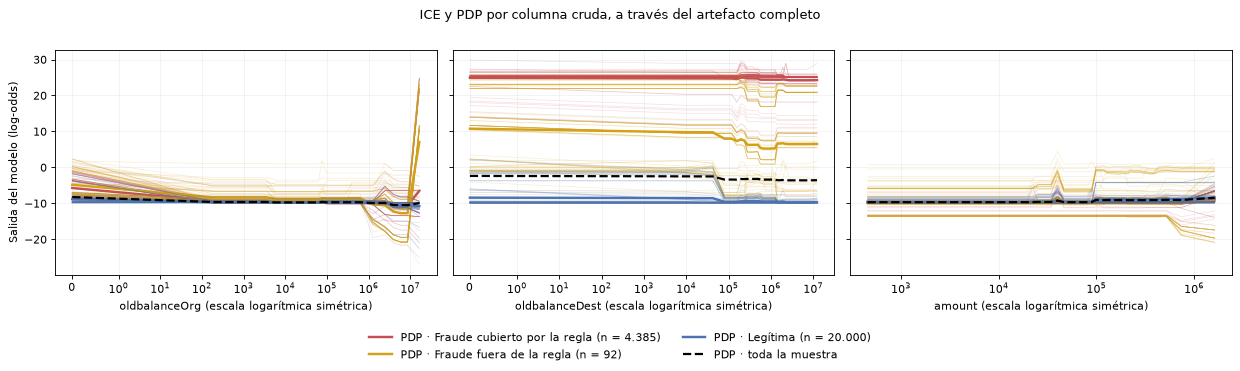

In [10]:
figure = plot_ice(curves, groups, ICE_CURVES_PER_GROUP)
plt.show()

**Figura 3.** El hallazgo central está en el panel del medio. **El PDP de `oldbalanceDest` sobre
toda la muestra va de −3,6 a −2,4 log-odds y no describe a ninguna fila real.** Promedia tres
comportamientos que no se parecen: los fraudes con la firma, arriba de +24 y casi planos; los que la
regla no ve, entre +5 y +11; las legítimas, cerca de −9. El promedio, la línea negra punteada, cae
entre los grupos y lejos de los tres. Y la muestra tiene 18% de fraude y no el 0,077% de la
población, así que su PDP tampoco es el de la población. **Por eso el PDP solo engaña:** el
promedio de curvas que no se parecen puede ser una curva que ninguna fila sigue, y solo las ICE lo
muestran.

En los otros dos paneles:

- **`oldbalanceOrg`, fraudes con la firma: el modelo sin la firma.** Al mover el saldo, la igualdad
  con el monto se rompe y la bandera pasa a 0. Su PDP queda entre −10,56 y −5,72, debajo del umbral
  en toda la grilla: sin la firma, el modelo los puntúa en promedio como legítimas. Es la limitación
  que el ADR 0011 declaró, leída como resultado, y tiene una consecuencia operativa directa: **si el
  agente de fraude dejara de vaciar las cuentas al centavo, el modelo puntuaría en promedio como
  legítimos a los fraudes que hoy atrapa por la firma**, 4.385 en referencia. Cuántos perdería
  exactamente no está medido. Por eso la fase 4 vigila la precisión de la regla como canario: si
  cae, el agente cambió.
- **`oldbalanceOrg`, fraudes fuera de la regla:** su PDP recorre casi 20 log-odds, de −12,74 a
  +7,03, y sube recién en el extremo alto de la grilla; 27 de los 92 tienen un saldo por encima del
  último punto.
- **`amount`:** las curvas casi no se mueven en esta grilla, y para los fraudes fuera de la regla
  eso no dice nada, porque la grilla termina antes de donde están ellos (sección 6).

**Por qué en log-odds y no en probabilidad.** Las salidas van de −20 a +35. En probabilidad, todo
lo que está por encima de +5 se aplasta contra 1 y todo lo que está por debajo de −5 contra 0, y
los tres grupos se verían como dos rectas planas. En log-odds las diferencias se ven, y la escala es
la misma de los valores SHAP: lo que sube una curva aquí es lo que una feature aporta en un
waterfall.

## 5. Cuatro casos locales

**El umbral.** El proyecto no tenía umbral declarado, y se toma el que elige la métrica de
decisión: recall con precisión ≥ 0,99 sobre los puntajes del artefacto en las 5.787.030 filas de
referencia (ADR 0011). Es *in-sample*, y por eso optimista; producción no participó en elegirlo. Es
la misma constante con la que la fase 4 monitorea producción, y la celda lo verifica.

**Los casos** se eligieron con un criterio declarado **antes de medir**, en el docstring de
`explain/local_explain.py`, entre las filas de la muestra:

- **a.** Un fraude que marcan la regla y el modelo: la fila de puntaje mediano entre ellos.
- **b.** Un fraude que el modelo marca y la regla no, los fraudes para los que el modelo existe: la
  de puntaje mediano.
- **c.** Un falso positivo del modelo: la legítima marcada de mayor puntaje.
- **d.** Una legítima cerca del umbral: la legítima no marcada de mayor puntaje.

In [11]:
point = operating_point(labels, scores.to_numpy())
assert point.threshold == OPERATING_THRESHOLD
flagged = scores >= point.threshold
fraud = pd.Series(labels == 1, index=raw_rows.index)
log_odds_threshold = np.log(point.threshold / (1 - point.threshold))
print(f"Umbral {point.threshold!r} ({log_odds_threshold:.4f} en log-odds), el del monitoreo")
print(
    f"Marca {point.flagged}: {point.true_positives} fraudes y "
    f"{point.flagged - point.true_positives} legítimas; precisión {point.precision:.6f}, "
    f"recall {point.recall:.6f}"
)
covered, missed = fraud & rule_flags, fraud & ~rule_flags
print(
    f"Fraudes que la regla cubre: {int(covered.sum())}, el modelo marca "
    f"{int((covered & flagged).sum())}. Fraudes fuera de la regla: {int(missed.sum())}, "
    f"el modelo marca {int((missed & flagged).sum())}"
)
cases = select_cases(
    sample[TARGET_COLUMN], scores.loc[sample.index], rule_flags.loc[sample.index], point.threshold
)
rows = []
for case, row_id in cases.items():
    raw = sample_rows.loc[row_id]
    top = top_contributions(result.values.loc[row_id])
    rows.append(
        {
            "caso": case,
            "fila": row_id,
            **{
                name: f"{raw[name]:.2f}" if name in MONEY else raw[name]
                for name in MODEL_INPUT_COLUMNS
            },
            "etiqueta": int(sample.loc[row_id, TARGET_COLUMN]),
            "regla": bool(rule_flags[row_id]),
            "probabilidad": scores[row_id],
            "log-odds": result.raw_output[row_id],
            "tres aportes mayores": ", ".join(f"{n} {v:+.2f}" for n, v in top.items()),
        }
    )
pd.DataFrame(rows).set_index("caso")

Umbral 0.42775088540908546 (-0.2910 en log-odds), el del monitoreo
Marca 4510: 4466 fraudes y 44 legítimas; precisión 0.990244, recall 0.997543
Fraudes que la regla cubre: 4385, el modelo marca 4385. Fraudes fuera de la regla: 92, el modelo marca 81


,fila,step,type,amount,oldbalanceOrg,oldbalanceDest,etiqueta,regla,probabilidad,log-odds,tres aportes mayores
caso,,,,,,,,,,,
a,5186345,361,CASH_OUT,140807.76,140807.76,137903.30,1,True,1,25.1288,"amount_equals_origin_balance +34.88, oldbalanceOrg -0.37, type_CASH_OUT +0.18"
b,3163674,237,TRANSFER,10000000.00,13924102.18,0.00,1,False,0.999992,11.7405,"amount +15.43, oldbalanceOrg +11.59, type_TRANSFER -3.42"
c,2958457,230,CASH_OUT,581769.38,0.00,0.00,0,False,0.546954,0.188371,"oldbalanceDest +4.03, oldbalanceOrg +2.80, amount +1.49"
d,472816,19,CASH_OUT,433504.72,0.00,0.00,0,False,0.265983,-1.0151,"oldbalanceDest +3.94, oldbalanceOrg +2.57, amount +1.21"


**El umbral en términos operativos.** Por qué este y no 0,5, el corte por defecto de `predict`:
con `scale_pos_weight` 34,9 las probabilidades no están calibradas, y 0,5 no corresponde a ningún
compromiso declarado; este es el que la métrica de decisión elige, el de más fraude con la cola
limpia (ADR 0011). En referencia marca 4.510 transacciones en 16,7 días simulados: unas 270 por
día, de las que unas 2,6 son legítimas (cuenta sobre las cifras de arriba). Es *in-sample* y por
eso optimista. Sobre producción, que no vio, la fase 4 midió unas 261 por día y una sola legítima
en 14 días (EVAL-011). Cada legítima es una revisión que no encuentra nada; las horas de analista
no se afirman, porque el tiempo por revisión no está medido.

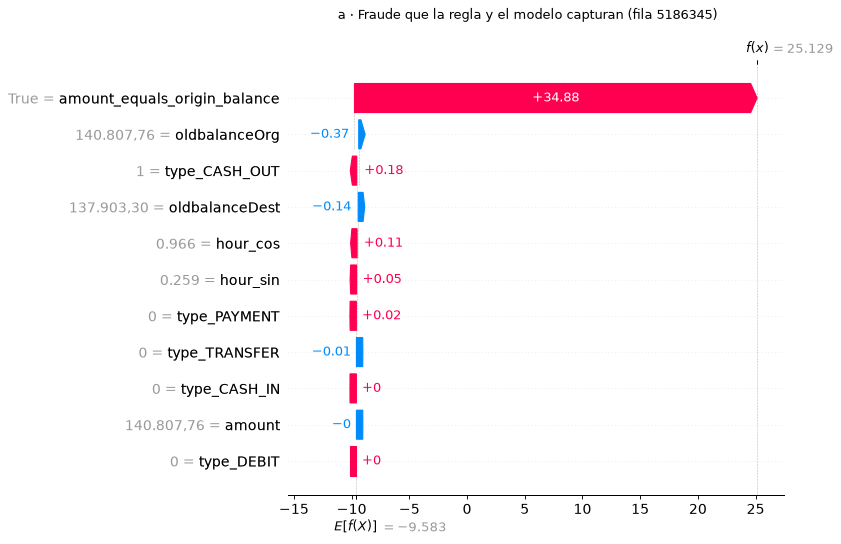

In [12]:
row_id = cases[CASE_RULE_AND_MODEL]
features_row = result.features.loc[row_id]
figure = plot_waterfall(
    result.values.loc[row_id],
    result.base_value,
    display_values(sample_rows.loc[row_id], features_row),
    features_row,
    f"{CASE_TITLES[CASE_RULE_AND_MODEL]} (fila {row_id})",
)
plt.show()

**Figura 4, caso a: el modelo marca esta transacción por una sola razón, que se lleva el saldo
completo de la cuenta.** La bandera aporta +34,88 log-odds, y las otras diez features juntas,
−0,17. Aquí el modelo reproduce la regla, como debía. **Es el caso típico de la cola de
revisión:** 4.385 de las 4.510 transacciones que el modelo marca en referencia se parecen a esta,
y para ellas el modelo no agrega nada a la regla salvo confirmarla. Su valor está en las 125
restantes.

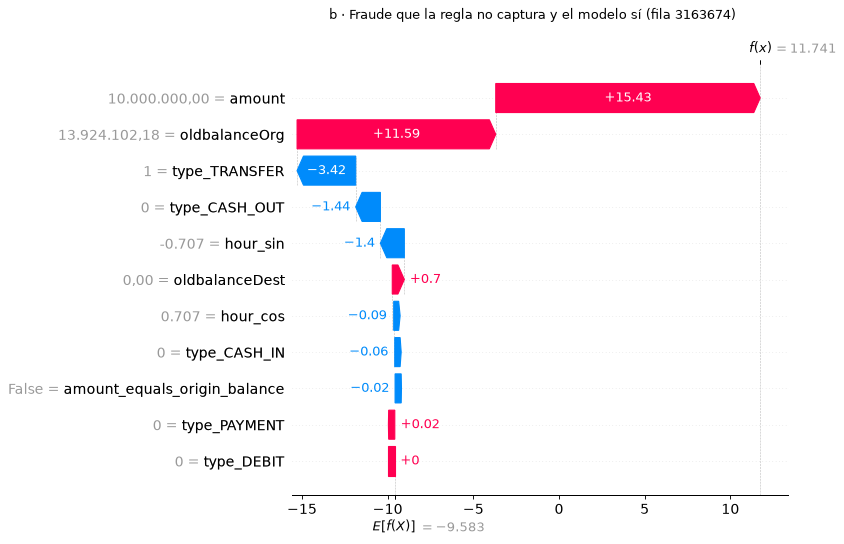

In [13]:
row_id = cases[CASE_MODEL_ONLY]
features_row = result.features.loc[row_id]
figure = plot_waterfall(
    result.values.loc[row_id],
    result.base_value,
    display_values(sample_rows.loc[row_id], features_row),
    features_row,
    f"{CASE_TITLES[CASE_MODEL_ONLY]} (fila {row_id})",
)
plt.show()

**Figura 5, caso b, el que importa: una transferencia de 10.000.000 desde una cuenta con
13.924.102,18, que la regla no ve porque no vacía la cuenta, y que el modelo marca porque el monto
es grande y el saldo de origen es todavía mayor.** La probabilidad es 0,999992. El monto aporta
+15,43 y el saldo de origen +11,59; el tipo resta, con `type_TRANSFER` en −3,42 y `type_CASH_OUT`
en 0, −1,44. Para esto existe un modelo encima de la regla.

**El +15,43 no es el aporte de los 10.000.000 exactos.** El corte más alto del modelo sobre
`amount` está en 2.812.983,54 (sección 6): para el modelo, esta transferencia es igual a una de
3.000.000. El +15,43 es lo que aporta "monto grande", y lo que vuelve fraude a la fila es la
combinación con el saldo. La celda siguiente lo mide sobre todas las transacciones de referencia
con esa misma cifra.

In [14]:
# Toda transacción de referencia con un monto de exactamente 10.000.000, la cifra del
# caso b, contada con la misma función que mide la regla.
label = reference[TARGET_COLUMN]
ten_million = (raw_rows["amount"] == 10_000_000).to_numpy()
outside_rule = ten_million & ~rule_flags.to_numpy()
larger_balance = ten_million & (raw_rows["oldbalanceOrg"] > raw_rows["amount"]).to_numpy()
counts = {
    "monto 10.000.000": profiling.rule_outcome(ten_million, label),
    "ídem, fuera de la regla": profiling.rule_outcome(outside_rule, label),
    "ídem, saldo de origen mayor que el monto": profiling.rule_outcome(larger_balance, label),
    "las que marca el modelo": profiling.rule_outcome(ten_million & flagged.to_numpy(), label),
}
print(profiling.label_by_type(reference[ten_million]).counts.to_string())
pd.DataFrame(
    {
        "transacciones": [o.flagged_rows for o in counts.values()],
        "fraudes": [o.true_positives for o in counts.values()],
        "legítimas": [o.false_positives for o in counts.values()],
        "precisión como regla": [o.precision for o in counts.values()],
    },
    index=list(counts),
)

isFraud      0    1  total
type                      
CASH_IN      0    0      0
CASH_OUT     0   57     57
DEBIT        0    0      0
PAYMENT      0    0      0
TRANSFER  2900   57   2957
total     2900  114   3014


,transacciones,fraudes,legítimas,precisión como regla
monto 10.000.000,3014,114,2900,0.0378235
"ídem, fuera de la regla",2957,57,2900,0.0192763
"ídem, saldo de origen mayor que el monto",57,57,0,1
las que marca el modelo,114,114,0,1


**La medición que cierra el caso b.** En referencia hay 3.014 transacciones de exactamente
10.000.000: 114 fraudes y **2.900 legítimas**. Como regla, "monto igual a 10.000.000" tendría
precisión 0,038: de cada 26 transacciones marcadas, una sería fraude. Fuera de la regla quedan
57 fraudes de esa cifra contra las mismas 2.900 legítimas, que son todas `TRANSFER`, como el
caso b: ni el monto ni el tipo separan al caso b de ellas. **El modelo marca los 114 fraudes y
ninguna de las 2.900 legítimas.**
No puede estar usando la cifra exacta: las 3.014 caen del mismo lado de cada uno de sus cortes
sobre `amount`. Lo que las separa es el saldo de origen: los 57 fraudes que la regla no ve
tienen un saldo mayor que el monto, y de las 2.900 legítimas, ninguna.

La historia del tope del simulador queda descartada dos veces: los 10.000.000 no son exclusivos
del fraude, porque 2.900 legítimas comparten la cifra, y no son un máximo por transacción,
porque el monto de referencia llega a 92.445.516,64 (sección 6).

**Por qué esta lectura vale más que la del tope.** Un modelo que hubiera aprendido "monto de
exactamente 10.000.000" habría aprendido un accidente de este simulador. No serviría en ningún
otro sistema de pagos, donde esa cifra no significa nada, y aquí mismo marcaría 2.900
legítimas, 174 revisiones inútiles por día (cuenta: 2.900 en 16,7 días). Lo que aprendió es
"monto grande en relación con el saldo de la cuenta": una transferencia muy grande desde una
cuenta que tiene todavía más. Es un patrón con sentido fuera del simulador. Que funcione con
datos reales no está medido: es un argumento sobre la forma de lo aprendido, no una medición,
y un atacante real no tiene por qué comportarse como el agente de PaySim.

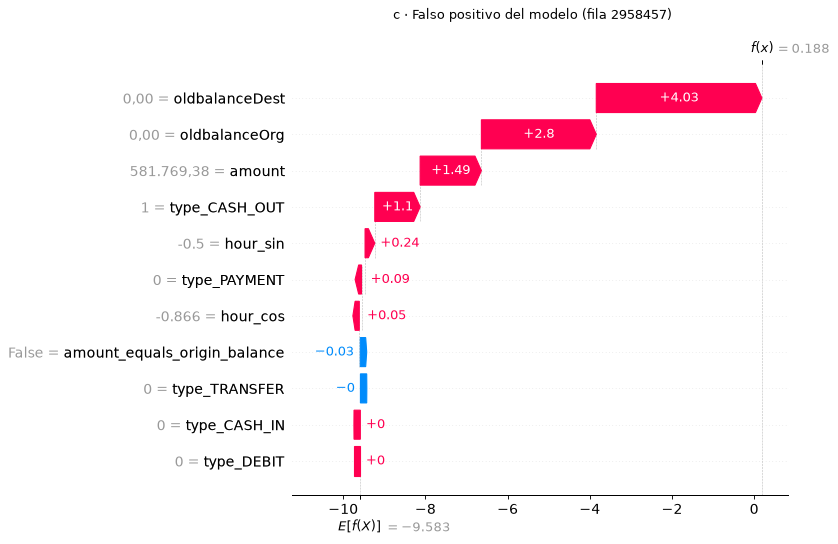

In [15]:
row_id = cases[CASE_FALSE_POSITIVE]
features_row = result.features.loc[row_id]
figure = plot_waterfall(
    result.values.loc[row_id],
    result.base_value,
    display_values(sample_rows.loc[row_id], features_row),
    features_row,
    f"{CASE_TITLES[CASE_FALSE_POSITIVE]} (fila {row_id})",
)
plt.show()

**Figura 6, caso c: un retiro grande entre dos cuentas con saldo cero, que el modelo marca sin la
firma y que era legítimo.** Son 581.769,38 desde un origen con saldo 0 hacia un destino con saldo
0. La bandera aporta −0,03; los dos saldos en cero y el monto empujan hacia fraude, +4,03, +2,80 y
+1,49, y el modelo lo marca con 0,547 contra un umbral de 0,428. Es la única legítima de la muestra
que el modelo marca, de 44 en toda la referencia. **Su costo operativo es una revisión que no
encuentra nada**; en referencia son unas 2,6 por día, y cuántas horas son no está medido.

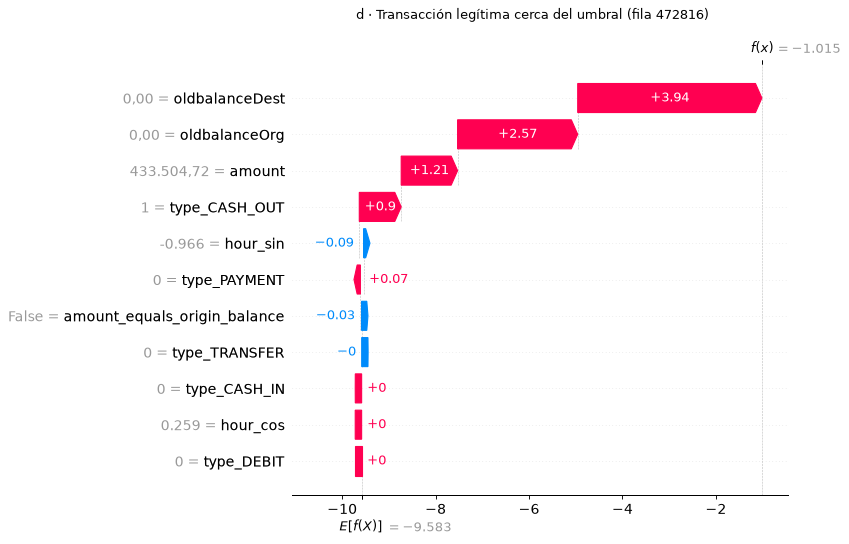

In [16]:
row_id = cases[CASE_NEAR_THRESHOLD]
features_row = result.features.loc[row_id]
figure = plot_waterfall(
    result.values.loc[row_id],
    result.base_value,
    display_values(sample_rows.loc[row_id], features_row),
    features_row,
    f"{CASE_TITLES[CASE_NEAR_THRESHOLD]} (fila {row_id})",
)
plt.show()

**Figura 7, caso d: el mismo perfil que el falso positivo, con empujes más chicos, y por eso
debajo del umbral.** Un `CASH_OUT` de 433.504,72 con los dos saldos en cero, y las mismas tres
features empujando hacia fraude en el mismo orden: +3,94, +2,57 y +1,21. Queda en 0,266.

In [17]:
# Si el umbral bajara hasta el puntaje del caso d, ¿cuánto más mandaría a revisión?
case_d = scores[cases[CASE_NEAR_THRESHOLD]]
lowered = profiling.rule_outcome((scores >= case_d).to_numpy(), reference[TARGET_COLUMN])
legitimate_now = point.flagged - point.true_positives
print(f"Umbral en el puntaje del caso d, {case_d:.4f}: marca {lowered.flagged_rows}")
print(
    f"Respecto del umbral de operación: {lowered.true_positives - point.true_positives} "
    f"fraudes más y {lowered.false_positives - legitimate_now} legítimas más"
)

Umbral en el puntaje del caso d, 0.2660: marca 4737
Respecto del umbral de operación: 9 fraudes más y 218 legítimas más


**Los casos c y d comparten perfil y se separan solo por magnitud.** Los dos son `CASH_OUT`
legítimos con los dos saldos en cero y un monto alto, y en los dos empujan las mismas features
en el mismo orden. En c los empujes suman más, y la salida, 0,188 log-odds, queda por encima
del umbral, −0,2910; en d, con −1,015, queda debajo. Para las legítimas, el borde de decisión
pasa por esa combinación de saldos en cero, `CASH_OUT` y monto alto, y lo que separa a una de
la otra es el tamaño de cada empuje, no un rasgo distinto.

**Qué pasaría si el umbral se moviera hasta d.** El modelo atraparía 9 fraudes más en
referencia y mandaría a revisión 218 legítimas más: unas 13 revisiones inútiles más por día
para medio fraude más por día (cuenta: 16,7 días). Es el costo de bajar el umbral en el borde
donde viven c y d, y es por qué el umbral se fija con un piso de precisión y no persiguiendo
fraudes sueltos.

## 6. Las limitaciones, medidas

### 6.1 La grilla del ICE de `amount` no llega a los fraudes que importan

La grilla de cuantiles termina en el cuantil 0,99 de `amount`, 1.621.796,86: ahí está el 99% de
las transacciones de referencia, y cada punto de la grilla tiene datos cerca. Pero los fraudes que
la regla no cubre, los que el modelo existe para atrapar, viven en la cola. La celda cuenta, por
grupo, de qué lado de la grilla cae el monto de cada fila.

In [18]:
quantile_grid = curves[FULL_RANGE_COLUMN].columns.to_numpy(dtype=float)
sides = grid_side(sample_rows[FULL_RANGE_COLUMN], quantile_grid)
print(f"Grilla de cuantiles: {quantile_grid[0]:.2f} a {quantile_grid[-1]:.2f}")
pd.crosstab(groups, sides).rename(
    columns={"below": "debajo", "inside": "dentro", "above": "encima"}
)

Grilla de cuantiles: 454.22 a 1621796.86


side,debajo,dentro,encima
group,,,
Fraude cubierto por la regla,22,3348,1015
Fraude fuera de la regla,4,30,58
Legítima,195,19621,184


De los 92 fraudes que la regla no cubre, **58 tienen un monto por encima del último punto de la
grilla y 4 por debajo del primero**, y solo 30 caen dentro. El documento de registro decía "62
tienen un monto mayor": 62 son los que caen **fuera**, por los dos lados, y el texto los leyó como
si fueran de uno (ERR-024). Por encima hay 58, y 57 de ellos son los de exactamente 10.000.000 de
la sección 5.

**Los 4 de abajo son parte de la lectura.** Tienen `amount` 0: son el caso degenerado que el ADR
0006 sacó de la firma, porque un movimiento de cero sobre un saldo de cero no se lleva nada. Son
fraudes que no mueven dinero: el agente intentó vaciar una cuenta que ya estaba vacía. La celda
siguiente mira qué hace el modelo con ellos.

In [19]:
zero_amount = sample.index[(sample["amount"] == 0) & (sample[TARGET_COLUMN] == 1)]
pd.DataFrame(
    {
        "tipo": sample_rows.loc[zero_amount, "type"],
        "oldbalanceOrg": sample_rows.loc[zero_amount, "oldbalanceOrg"],
        "probabilidad": scores.loc[zero_amount],
        "marcado": flagged.loc[zero_amount],
        "tres aportes mayores": [
            ", ".join(f"{n} {v:+.2f}" for n, v in top_contributions(result.values.loc[i]).items())
            for i in zero_amount
        ],
    }
)

,tipo,oldbalanceOrg,probabilidad,marcado,tres aportes mayores
2736447,CASH_OUT,0,0.912159,True,"type_CASH_OUT +3.92, oldbalanceDest +2.81, oldbalanceOrg +2.78"
3247298,CASH_OUT,0,0.914743,True,"type_CASH_OUT +3.94, oldbalanceOrg +2.80, oldbalanceDest +2.77"
3760289,CASH_OUT,0,0.548338,True,"type_CASH_OUT +3.29, amount +3.02, oldbalanceOrg +1.78"
5563714,CASH_OUT,0,0.849609,True,"type_CASH_OUT +3.35, amount +3.03, oldbalanceOrg +1.69"


**El modelo marca los cuatro**, con probabilidades de 0,55 a 0,91, y los empuja el mismo patrón
que produjo el falso positivo c: `CASH_OUT` y saldos en cero. Es la otra cara del caso c. El patrón
"retiro desde una cuenta vacía" atrapa estos fraudes y también marca alguna legítima con ese
perfil.

**Su consecuencia operativa es la contraria de la de los fraudes de la cola.** El costo de dejar
pasar un fraude es su monto (ROADMAP, sección 1.1), y el de estos cuatro es cero: atraparlos no
evita ninguna pérdida, aunque sí descubre un intento de fraude. Los fraudes que pesan son los 58 de
la cola, y esos son los que la grilla de cuantiles no ve.

In [20]:
thresholds = raw_split_thresholds(pipeline, FULL_RANGE_COLUMN)
print(f"Nodos que cortan sobre {FULL_RANGE_COLUMN}: {len(thresholds)}")
print(f"El corte más alto, en moneda: {thresholds[-1]:.2f}")
print(
    f"Cortes por encima del último punto de la grilla de cuantiles: "
    f"{int((thresholds > quantile_grid[-1]).sum())}"
)

Nodos que cortan sobre amount: 1227
El corte más alto, en moneda: 2812983.54
Cortes por encima del último punto de la grilla de cuantiles: 53


**El corte más alto del modelo sobre `amount` está en 2.812.983,54.** Por encima de ese valor, su
salida no puede depender de `amount`: para el modelo, 10.000.000 es lo mismo que 3.000.000. Y 53 de
sus 1.227 cortes sobre `amount` caen entre el fin de la grilla de cuantiles y ese valor, en un tramo
que la figura 3 no recorre. Por qué no hay cortes más arriba no está medido. LightGBM agrupa cada
feature en a lo sumo 255 intervalos antes de buscar cortes; que el último intervalo empiece cerca
de ahí es una hipótesis.

### 6.2 La segunda figura: `amount` sobre su rango completo

La grilla de rango completo va del menor monto positivo de referencia al mayor, con 60 puntos
espaciados en escala logarítmica, más el 0 (`log_grid`). Las curvas son las mismas ICE, por el
mismo artefacto completo y con la bandera recalculada en cada punto.

In [21]:
full_grid = log_grid(raw_rows[FULL_RANGE_COLUMN])
full = ice_curves(pipeline, sample_rows, FULL_RANGE_COLUMN, full_grid)
full_pdp = full.groupby(groups).mean()
full_pdp.loc["Toda la muestra"] = full.mean()
print(
    f"Grilla de rango completo: {len(full_grid)} puntos, {full_grid[0]:.2f} a {full_grid[-1]:.2f}"
)
print(f"El primer punto positivo: {full_grid[1]:.2f}")
pd.DataFrame({"mín.": full_pdp.min(axis=1), "máx.": full_pdp.max(axis=1)})

Grilla de rango completo: 61 puntos, 0.00 a 92445516.64
El primer punto positivo: 0.01


,mín.,máx.
group,,
Fraude cubierto por la regla,-10.0692,-8.74144
Fraude fuera de la regla,-10.0475,8.98051
Legítima,-9.62685,-8.22594
Toda la muestra,-9.66516,-8.34776


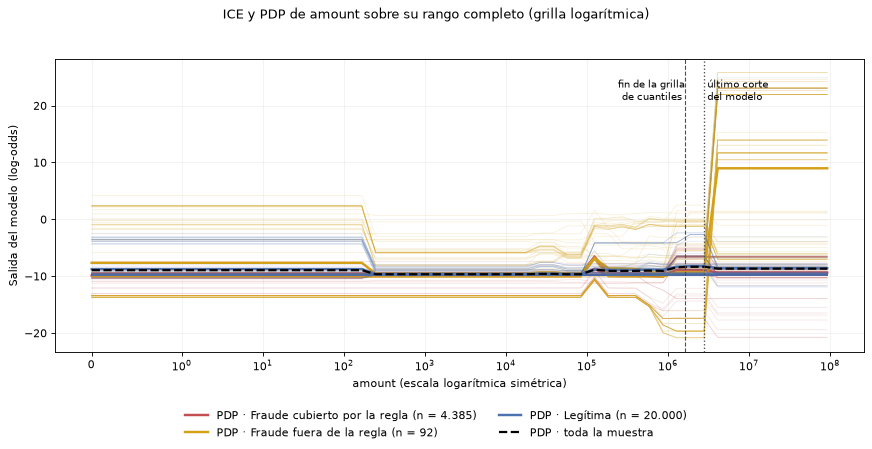

In [22]:
figure = plot_ice({FULL_RANGE_COLUMN: full}, groups, ICE_CURVES_PER_GROUP)
figure.set_size_inches(11, 5.6)
figure.tight_layout(rect=(0, 0.1, 1, 0.95))
figure.suptitle(f"ICE y PDP de {FULL_RANGE_COLUMN} sobre su rango completo (grilla logarítmica)")
for ax in figure.axes:
    ax.axvline(thresholds[-1], color="0.3", ls=":", lw=1.2)
    ax.axvline(quantile_grid[-1], color="0.3", ls="--", lw=1)
figure.axes[0].text(
    quantile_grid[-1], 21, "fin de la grilla\nde cuantiles ", ha="right", fontsize=9
)
figure.axes[0].text(thresholds[-1], 21, " último corte\n del modelo", ha="left", fontsize=9)
plt.show()

**Figura 8.** La línea discontinua es el fin de la grilla de cuantiles, 1.621.796,86; la punteada,
el corte más alto del modelo, 2.812.983,54. Entre las dos está lo que la figura 3 no veía: **el PDP
de los fraudes fuera de la regla salta de cerca de −10 a casi +9 log-odds**, y de ahí en adelante
queda plano hasta los 92 millones. Ese salto es el que lleva a los fraudes de la cola por encima del
umbral, y la grilla de cuantiles termina justo antes. Las legítimas y los fraudes con la firma casi
no se mueven en todo el rango: sus PDP van de −9,63 a −8,23 y de −10,07 a −8,74.

**Qué hace el modelo con todo lo que está por encima de su último corte.** La celda siguiente
cuenta las transacciones de referencia con monto mayor que 2.812.983,54, donde `amount` ya no le
dice nada al modelo, y cuáles marca.

In [23]:
above_cut = (raw_rows[FULL_RANGE_COLUMN] > thresholds[-1]).to_numpy()
label = reference[TARGET_COLUMN]
pd.DataFrame(
    {
        name: {
            "transacciones": outcome.flagged_rows,
            "fraudes": outcome.true_positives,
            "legítimas": outcome.false_positives,
        }
        for name, outcome in {
            "monto por encima del último corte": profiling.rule_outcome(above_cut, label),
            "ídem, marcadas por el modelo": profiling.rule_outcome(
                above_cut & flagged.to_numpy(), label
            ),
        }.items()
    }
).T

,transacciones,fraudes,legítimas
monto por encima del último corte,22844,658,22186
"ídem, marcadas por el modelo",659,658,1


Por encima del último corte hay 22.844 transacciones de referencia, 658 fraudes y 22.186
legítimas: como regla, "monto grande" tendría precisión 0,029. **El modelo marca los 658 fraudes y
una sola legítima.** Es la medición del caso b a escala de toda la cola: el monto grande solo no
alcanza, y lo que separa es la relación con el saldo y el tipo de operación. Sin esa relación, un
"monto grande" mandaría a revisión unas 1.330 legítimas por día (cuenta: 22.186 en 16,7 días).

**Las dos figuras conviven, y la razón es esta.** La grilla de cuantiles pone sus puntos donde
están los datos: el 98% central de la referencia, con filas reales cerca de cada punto. La de rango
completo recorre la cola donde viven los fraudes que el modelo existe para atrapar, pero ahí casi no
hay filas, y sus puntos altos son montos que pocas transacciones tienen: las curvas evalúan al
modelo en combinaciones raras. La primera sola no ve la cola; la segunda sola exagera lo que pasa
en ella. Juntas cuentan lo que el modelo hace con `amount`.

### 6.3 Lo que esta medición no permite concluir

- **Nada sobre la generalización.** Todo es *in-sample*. La fase 4 la midió después, con el mismo
  artefacto y el mismo umbral: sobre producción, recall 0,9976 y precisión 0,9997 (EVAL-011).
- **La importancia por permutación** de la bandera, `amount` y `oldbalanceOrg` incluye filas fuera
  del dominio del modelo (sección 3); cuánto pesan en la caída no está medido.
- **El PDP de toda la muestra** promedia sobre 18% de fraude, no sobre el 0,077% de la población.
- **Los 11 fraudes** que la regla no cubre y el modelo tampoco marca no se analizaron.

## 7. La explicación viaja con el modelo

Las figuras y tablas de este análisis —las que `scripts/run_interpretability.py` escribe en
`reports/interpretability/`, incluida la de rango completo— están adjuntas a la **versión 1** de
`fraud-detection-pipeline` en el Model Registry de MLflow: en la corrida que la registró,
`e1fb3e9b12ed4dfc9a025a751eb9ff04`, bajo la carpeta `interpretability/`, con etiquetas en la
versión que dicen dónde están, qué script las produjo y desde qué commit. Antes de subir nada, la
función que las adjunta (`registry.log_version_artifacts`) comprueba que la versión se registró a
partir de este mismo artefacto, por su sha256: la explicación no puede terminar colgada de otro
modelo.

Es lo que el módulo 4.4 llama explicabilidad en producción y rastro de auditoría: quien abre la
versión 1 encuentra, junto al modelo, por qué decide lo que decide, y no solo sus métricas. Este
notebook no escribe en MLflow: ejecutarlo no necesita red ni credenciales.